In [1]:
# BTVN2: Thay đổi ngưỡng dự đoán Logistic Regression
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score,
    confusion_matrix, classification_report)

# Tạo dữ liệu
np.random.seed(42)

# Tạo 300 BMI từ 15 đến 40
BMI = np.random.uniform(15, 40, 300)

# Xác suất mắc bệnh tăng khi BMI tăng
probability = 1 / ( 1 + np.exp(-(BMI - 27) / 2))

# Sinh nhãn 0 hoặc 1
y = np.random.binomial(1, probability)

# Chuyển BMI thành ma trận 2 chiều
X = BMI.reshape(-1, 1)

# Chia dữ liệu
X_train, X_test, y_train, y_test = train_test_split(X, y,
    test_size=0.2, random_state=42)

# Tạo mô hình
model = LogisticRegression()

# Huấn luyện
model.fit(X_train, y_train)

# Lấy xác suất thuộc lớp 1
y_probability = model.predict_proba(X_test)[:, 1]

# Các ngưỡng cần kiểm tra
thresholds = [0.5, 0.6, 0.7]

for threshold in thresholds:
    # Chuyển xác suất thành nhãn
    y_pred = (y_probability >= threshold).astype(int)

    # Tính Accuracy
    accuracy = accuracy_score(y_test, y_pred)

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)

    print("\n==============================")
    print("NGƯỠNG:", threshold)

    print("Accuracy:", accuracy)

    print("\nConfusion Matrix:")

    print(cm)

    print("\nClassification Report:")

    print(classification_report( y_test, y_pred, zero_division=0))


NGƯỠNG: 0.5
Accuracy: 0.8833333333333333

Confusion Matrix:
[[25  3]
 [ 4 28]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.89      0.88        28
           1       0.90      0.88      0.89        32

    accuracy                           0.88        60
   macro avg       0.88      0.88      0.88        60
weighted avg       0.88      0.88      0.88        60


NGƯỠNG: 0.6
Accuracy: 0.85

Confusion Matrix:
[[25  3]
 [ 6 26]]

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85        28
           1       0.90      0.81      0.85        32

    accuracy                           0.85        60
   macro avg       0.85      0.85      0.85        60
weighted avg       0.85      0.85      0.85        60


NGƯỠNG: 0.7
Accuracy: 0.8666666666666667

Confusion Matrix:
[[27  1]
 [ 7 25]]

Classification Report:
              precision    recall  f1-score   su

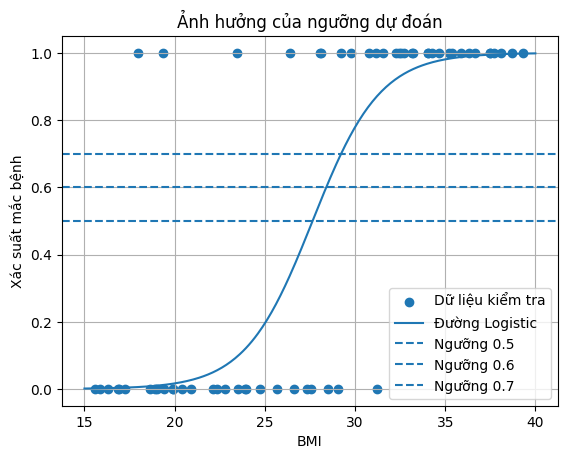

In [2]:
import matplotlib.pyplot as plt

# Tạo dãy BMI
BMI_range = np.linspace(15, 40, 300).reshape(-1, 1)

# Tính xác suất
prob_range = model.predict_proba(BMI_range)[:, 1]

# Vẽ dữ liệu
plt.scatter(X_test[:, 0], y_test, label="Dữ liệu kiểm tra")

# Vẽ đường Logistic
plt.plot(BMI_range, prob_range, label="Đường Logistic")

# Các ngưỡng
plt.axhline(y=0.5, linestyle="--", label="Ngưỡng 0.5")
plt.axhline( y=0.6, linestyle="--", label="Ngưỡng 0.6")

plt.axhline( y=0.7, linestyle="--", label="Ngưỡng 0.7")

plt.xlabel("BMI")
plt.ylabel("Xác suất mắc bệnh")

plt.title("Ảnh hưởng của ngưỡng dự đoán")

plt.legend()
plt.grid()
plt.show()